# DSA 107 — Lab 5: Cleaning and combining data

**Week 5 · w/c 26 October 2026** · paired with DSA 101 lecture week 5

**Name:** Onur Gültekin  **Student ID:** 250221021024

---

### What you will produce

A runnable Colab notebook, pushed to your `dsa107-labs` repository. In it you clean a real, dirty table: you find missing values that are hiding, turn text into numbers, remove repeated rows, look at why values are missing and draw one labelled figure about it, and join a second table to the first one.

### Before you start

Run the setup cell below. If any import fails, run
`!pip install pandas matplotlib seaborn` in a new cell and try again.

### How to use this notebook

Every code cell has a **Goal** written just above it. Read the goal, then write the code. You do not need to open the handout while you work — everything you have to do is in this notebook.

Every Goal and every question shows how many **points** it is worth. The table below shows how they add up to the 10 code points.

Some lines are **already written for you**. Read them, run them, and do not change them.

A code cell only shows the result of its **last line**. A value on any other line shows **nothing**. If you want to see two or more things from one cell, put each of them inside `print()`.

Some goals end with a **Check:** line. If your number is not the same as the check, fix your code before you go on.

The **Command reference** below holds the commands you need for this lab, and a few more. Read it once now, and come back to it whenever you are stuck.

### How the 10 code points are shared

| Part | Where in this notebook | Points |
| --- | --- | --- |
| Looking at the data | Goals 1a, 1b (0.5 each) | 1 |
| Hidden missing values | Goal 2a | 1 |
| Text into numbers | Goal 3a | 1 |
| Repeated rows | Goals 4a, 4b (0.5 each) | 1 |
| Why is it missing? | Goal 5a | 1 |
| Figure | Goal 5b (needs an x label, a y label and a title) | 1 |
| Joining two tables | Goal 6a | 1 |
| Interpretation | Q1, Q2, Q3, Q4 (0.75 each) | 3 |
| **Total** | | **10** |

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
print("pandas", pd.__version__)

pandas 2.2.3


## Command reference

`df` means a whole table (a DataFrame). `s` means a single column (a Series).
Not every command here is needed for this lab — choosing the right one is part of the work.

**Looking at the table**

| Command | What it does |
| --- | --- |
| `df.head(n)` | returns the first `n` rows (5 if you do not say) |
| `df.shape` | gives (number of rows, number of columns) |
| `len(df)` | gives the number of rows |
| `df.dtypes` | what each column is stored as: `object` = text, `int64` / `float64` = numbers |
| `s.dtype` | the same, for one column only |
| `s.describe()` | count, mean, std, min, quartiles and max of one number column |

**Hunting for missing values — new this week**

| Command | What it does |
| --- | --- |
| `df.isna().sum()` | the number of missing values in each column. It only finds **real** missing values (`NaN`) |
| `s.isna().sum()` | the same, for one column only |
| `s.value_counts().head()` | the 5 most common values of a column, most common first |
| `(s == "-").sum()` | how many rows hold exactly the text `"-"` |
| `s.replace("-", pd.NA)` | changes every `"-"` into a real missing value. `pd.NA` means *missing* |
| `df["col"] = ...` | puts a column back into the table (a new one, or replacing the old one) |

**Text into numbers — new this week**

| Command | What it does |
| --- | --- |
| `s.str.replace("a", "b")` | in every value, changes the text `"a"` into `"b"` |
| `pd.to_numeric(s, errors="coerce")` | turns text into real numbers; anything that is not a number becomes `NaN` |
| `s / 1_000_000` | divides every value by one million (you may write `_` inside a number to make it easy to read) |

**Repeated rows — new this week**

| Command | What it does |
| --- | --- |
| `df.duplicated().sum()` | how many rows are an **exact** copy of a row above them (every column the same) |
| `df.duplicated(subset=["col"]).sum()` | how many rows repeat a value of `col` that appeared above them |
| `df.drop_duplicates(subset=["col"]).copy()` | keeps only the **first** row for every value of `col`, as a new, separate table |

**Missing values as a yes / no column**

| Command | What it does |
| --- | --- |
| `s.isna()` | a **boolean mask**: `True` for every row where the value is missing |
| `s.notna()` | the opposite: `True` where the value is **not** missing |
| `mask.sum()` / `mask.mean()` | how many rows are `True` / what **fraction** of the rows are `True` |
| `df.dropna(subset=["col"])` | removes the rows where `col` is missing (not needed today) |
| `s.fillna(s.median())` | fills the missing values with the median (not needed today) |

**Group summaries — from week 3**

| Command | What it does |
| --- | --- |
| `df.groupby("g")["x"].mean()` | splits the rows into groups by `g`, then gives the mean of `x` in each group |
| `.count()` `.sum()` | put one of these in place of `.mean()` for another summary |
| `s.round(2)` | rounds every value to 2 decimal places |

**Joining two tables — new this week**

| Command | What it does |
| --- | --- |
| `a.merge(b, on="key", how="left")` | adds the columns of `b` to `a`, matching the rows by the column `key`. `how="left"` keeps **every** row of `a` |
| `how="inner"` | keeps only the rows that match in **both** tables |
| `validate="one_to_one"` | add it inside `merge(...)`: pandas stops with an error if the key repeats in a table, instead of quietly making extra rows |
| `df[["a", "b"]]` | keeps only these columns — note the **double** brackets |

**Drawing and labelling**

The plot commands hand you back an *axes* object. Catch it in a variable (`ax = ...`) and you can label it.

| Command | What it does |
| --- | --- |
| `ax = s.plot.bar()` | draws a bar chart, one bar per row of `s` |
| `ax.set_xlabel("...")` | names the horizontal axis |
| `ax.set_ylabel("...")` | names the vertical axis |
| `ax.set_title("...")` | puts a title on the figure |
| `plt.show()` | shows the finished figure |

A figure in this course is not finished until it has both axis labels and a title.

## 1. Look at it

The lecture ended with a **cleaning checklist**: look at the table, look for missing values that hide, check the types, count the repeated rows, check every join, and write down what you changed. This notebook follows that list.

This week's dataset is **FiveThirtyEight's biopics table**: films about the life of a real person (*biopics*), released between 1915 and 2014. It was collected by hand, and it is **dirty** — that is why we use it. The columns you need today:

| Column | What it means |
| --- | --- |
| `title` | the name of the film |
| `site` | the address of the film's page on IMDb, the big film website |
| `year_release` | the year the film came out |
| `box_office` | how much money the film made in cinemas, in US dollars, **written as text**, for example `$18.3M` |
| `number_of_subjects` | how many real people the film is about |
| `subject` | the real person this row is about |
| `subject_sex` | `Male` or `Female` |

The file is saved in an older text format called **Latin-1**. Without `encoding="latin-1"`, `read_csv` stops with an error, so the loading line is written for you.

> **Goal 1a · 0.5 pt.** Load the CSV into a DataFrame called `bio` (this line is already written for you). Print the **shape** of the table, then show its **first five rows**.

In [3]:
bio_url = "https://raw.githubusercontent.com/fivethirtyeight/data/master/biopics/biopics.csv"
bio = pd.read_csv(bio_url, encoding="latin-1")

# TODO: print the shape
print(bio.shape)
# TODO: show the first five rows
bio.head()

(761, 14)


,title,site,country,year_release,box_office,director,number_of_subjects,subject,type_of_subject,race_known,subject_race,person_of_color,subject_sex,lead_actor_actress
0,10 Rillington Place,http://www.imdb.com/title/tt0066730/,UK,1971,-,Richard Fleischer,1,John Christie,Criminal,Unknown,NaN,0,Male,Richard Attenborough
1,12 Years a Slave,http://www.imdb.com/title/tt2024544/,US/UK,2013,$56.7M,Steve McQueen,1,Solomon Northup,Other,Known,African American,1,Male,Chiwetel Ejiofor
2,127 Hours,http://www.imdb.com/title/tt1542344/,US/UK,2010,$18.3M,Danny Boyle,1,Aron Ralston,Athlete,Unknown,NaN,0,Male,James Franco
3,1987,http://www.imdb.com/title/tt2833074/,Canada,2014,-,Ricardo Trogi,1,Ricardo Trogi,Other,Known,White,0,Male,Jean-Carl Boucher
4,20 Dates,http://www.imdb.com/title/tt0138987/,US,1998,$537K,Myles Berkowitz,1,Myles Berkowitz,Other,Unknown,NaN,0,Male,Myles Berkowitz


> **Goal 1b · 0.5 pt.** Print what each column is stored as (the **dtypes**). Then print the **number of missing values** in each column.
> Look at `box_office` in both lists. Remember what you see — Part 2 comes back to it.

In [4]:
# TODO: print the dtypes of every column
print(bio.dtypes)
# TODO: print the number of missing values in each column
print(bio.isna().sum())

title                 object
site                  object
country               object
year_release           int64
box_office            object
director              object
number_of_subjects     int64
subject               object
type_of_subject       object
race_known            object
subject_race          object
person_of_color        int64
subject_sex           object
lead_actor_actress    object
dtype: object
title                   0
site                    0
country                 0
year_release            0
box_office              0
director                0
number_of_subjects      0
subject                 0
type_of_subject         0
race_known              0
subject_race          197
person_of_color         0
subject_sex             0
lead_actor_actress      7
dtype: int64


## 2. Missing values that hide

`isna()` only finds **real** missing values (`NaN`). But a table often writes "missing" in its own way: `-`, `-99`, `"N/A"` or `"unknown"`. The lecture called these **sentinel values**: missing values that look like normal data. `isna()` cannot see them.

To find them, **look at the values themselves**. `value_counts()` puts the most common value first — and a sentinel is usually very common.

> **Goal 2a · 1 pt.** Show the **5 most common values** of `box_office`. One value at the top is not a box office at all. Print **how many rows** hold exactly that value.
> Then **replace** that value with `pd.NA` (a real missing value), put the column back into `bio`, and print the number of missing values in `box_office` again.
> **Check:** the last number must be the same as the count you printed before the replace.

In [5]:
# TODO: show the 5 most common values of box_office (inside print)
print(bio["box_office"].value_counts().head())
# TODO: print how many rows hold exactly that strange value
print((bio["box_office"] == "-").sum())
# TODO: replace that value with pd.NA and put the column back into bio
bio["box_office"] = bio["box_office"].replace("-", pd.NA)
# TODO: print the number of missing values in box_office again
print(bio["box_office"].isna().sum())

box_office
-         324
$6M         6
$11M        5
$340K       4
$11.6M      4
Name: count, dtype: int64
324
324


## 3. Numbers stored as text

`box_office` is stored as `object` — that means **text**. You cannot take the mean of text or draw it on a number axis.

Each value looks like `$56.7M` (M = million) or `$537K` (K = thousand). Python understands **`56.7e6`** as 56.7 × 1,000,000 and **`537e3`** as 537 × 1,000. So the first line of the next cell is **written for you**: it removes the `$`, changes `M` into `e6` and `K` into `e3`, and stores the result as `text`:

| `box_office` | `text` |
| --- | --- |
| `$56.7M` | `56.7e6` |
| `$537K` | `537e3` |

Your job is the last step: turn `text` into real numbers, in **millions of dollars**.

> **Goal 3a · 1 pt.** Run the ready-made line. Then turn `text` into numbers with `pd.to_numeric(..., errors="coerce")`, **divide by 1,000,000**, and store the result as a new column `bio["box_office_m"]`.
> Print the dtype of `box_office` and the dtype of `box_office_m`. Then show `describe()` of `box_office_m`.
> **Check:** in `describe()`, the `count` must be **437** and the `max` must be **350**.

In [6]:
# ready-made line: do not change it
text = bio["box_office"].str.replace("$", "").str.replace("M", "e6").str.replace("K", "e3")

# TODO: turn text into numbers (errors="coerce"), divide by 1_000_000, store as bio["box_office_m"]
bio["box_office_m"] = pd.to_numeric(text, errors="coerce") / 1_000_000
# TODO: print the dtype of box_office and the dtype of box_office_m
print("box_office:", bio["box_office"].dtype)
print("box_office_m:", bio["box_office_m"].dtype)
# TODO: show the describe() of box_office_m
print(bio["box_office_m"].describe())

box_office: object
box_office_m: float64
count    437.000000
mean      22.981174
std       38.311356
min        0.003150
25%        1.170000
50%        6.140000
75%       30.500000
max      350.000000
Name: box_office_m, dtype: float64


**Q1 · 0.75 pt.**
(a) Fill in: `bio` has **761** rows and **14** columns. In Goal 1b, `isna()` said that `box_office` has **0** missing values. After Goal 2a it has **324**. Before Goal 3a, `box_office` was stored as **object**; `box_office_m` is stored as **float64**.
(b) Why did `isna()` not find the missing values in Goal 1b? What does `-` mean in this column?


---

**Answer:**

**(b)** `isna()` only finds real missing values (NaN). In this table a missing box office is written as the text "-". This is a sentinel value, so it looks like normal data and `isna()` cannot see it. "-" means that the box office of that film is not known, so it is not a real amount of money. After I replaced it with `pd.NA`, `isna()` finds all 324.

## 4. Repeated rows

Before you remove repeated rows, ask: **what makes a row unique?**

Every film on IMDb has its **own page**, so its own `site` address. So `site` names one film. But look at `number_of_subjects`: some films are about two, three or four real people — and such a film has **one row per person**.

> **Goal 4a · 0.5 pt.** Print two numbers: how many rows are **exact** duplicates, and how many rows repeat a `site` that appeared above them.

In [7]:
# TODO: print how many rows are exact duplicates
print(bio.duplicated().sum())
# TODO: print how many rows repeat a site
print(bio.duplicated(subset=["site"]).sum())

0
89


> **Goal 4b · 0.5 pt.** Keep **one row per film**: drop the rows that repeat a `site` (use `.drop_duplicates(subset=["site"]).copy()`), and store the result as `films`. Print the number of rows in `bio` and the number of rows in `films`.
> **Check:** `films` must have **672** rows.

In [8]:
# TODO: keep one row per film (by site) and store it as films
films = bio.drop_duplicates(subset=["site"]).copy()
# TODO: print the number of rows in bio and in films
print("rows in bio:", len(bio))
print("rows in films:", len(films))

rows in bio: 761
rows in films: 672


**Q2 · 0.75 pt.**
(a) Fill in: exact duplicates **0** · rows repeating a site **89** · rows in `bio` **761** → rows in `films` **672**.
(b) What does **one row of `bio`** stand for, and what does **one row of `films`** stand for? Are the rows that repeat a site **mistakes**? (Hint: look at `number_of_subjects` and `subject`.)


---

**Answer:**

**(b)** One row of `bio` is one film for one subject. If a film is about three people, the same film has three rows and only the `subject` column changes. One row of `films` is one film, because I kept only the first row of every `site` (every IMDb page). The repeated rows are not mistakes. All of them belong to films with `number_of_subjects` 2, 3 or 4, and every row names a different person. For example 84 Charing Cross Road has one row for Frank Doel and one row for Helene Hanff. An exact duplicate would be a real error, and there are none (0). I dropped the 89 rows only because from now on I want one row per film.

## 5. Why is it missing?

Almost half of the films have no box office. Before you decide what to do about it, ask the lecture's question: **why is it missing?**

- **Missing at random:** nothing connects the missing rows. Dropping them is usually safe.
- **Missing for a reason you can see:** the missing rows are different in a way that **another column** shows.
- **Missing for a reason you cannot see:** no column can tell you. Say so in your report.

You can **look**: split the films by the **decade** they came out in, and compare how often the box office is missing in each decade. The `decade` column and the number of films in every decade (`n_films`) are **made for you** in the next cell.

A boolean mask helps again: `films["box_office_m"].isna()` is `True` for every film with no box office. Its **mean** in a group is the **share** of films in that group with no box office.

> **Goal 5a · 1 pt.** Run the two ready-made lines. Then add a column `bo_missing` to `films`: `True` when `box_office_m` is missing. Print **how many films** have no box office (the sum of `bo_missing`).
> Then find the **share** of films with no box office in every decade (the mean of `bo_missing` by `decade`, rounded to 2 decimal places), store it as `missing_share`, and print it.
> **Check:** 289 films have no box office.

In [9]:
# ready-made lines: do not change them
films["decade"] = films["year_release"] // 10 * 10      # 1987 becomes 1980
n_films = films.groupby("decade")["title"].count()      # number of films in every decade
print("number of films in every decade:")
print(n_films)
print()

# TODO: add the column bo_missing (True when box_office_m is missing)
films["bo_missing"] = films["box_office_m"].isna()
# TODO: print how many films have no box office
print(films["bo_missing"].sum())
# TODO: share of films with no box office in every decade, rounded to 2 decimals -> missing_share, and print it
missing_share = films.groupby("decade")["bo_missing"].mean().round(2)
print(missing_share)

number of films in every decade:
decade
1910      1
1920      2
1930     27
1940     42
1950     65
1960     36
1970     43
1980     63
1990    109
2000    182
2010    102
Name: title, dtype: int64

289
decade
1910    1.00
1920    1.00
1930    0.93
1940    0.90
1950    0.95
1960    0.75
1970    0.88
1980    0.30
1990    0.09
2000    0.21
2010    0.27
Name: bo_missing, dtype: float64


> **Goal 5b · Figure · 1 pt.** Draw a **bar chart** of `missing_share`: one bar per decade. Give it an x label, a y label and a title.

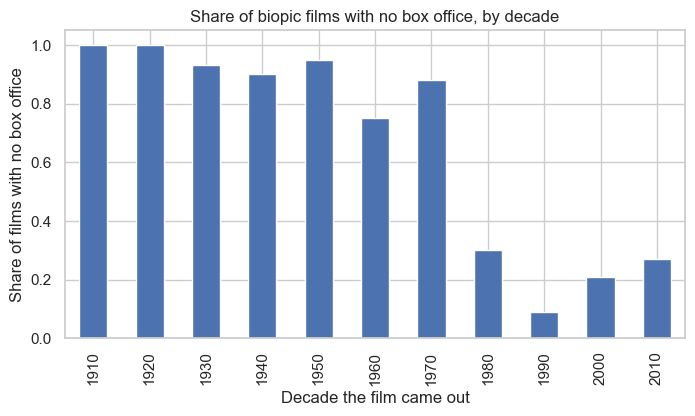

In [10]:
plt.figure(figsize=(8, 4))

# TODO: bar chart of missing_share
ax = missing_share.plot.bar()
# TODO: x label, y label and title
ax.set_xlabel("Decade the film came out")
ax.set_ylabel("Share of films with no box office")
ax.set_title("Share of biopic films with no box office, by decade")

plt.show()

**Q3 · 0.75 pt.**
(a) Fill in, looking only at decades with **at least 20 films**: the highest share of films with no box office is in the **1950**s (share **0.95**); the lowest is in the **1990**s (share **0.09**). The 1910s and 1920s bars are at 1.00 — why should you not trust those two bars much? (Look at `n_films`.)
(b) Is the box office missing **at random**, or **for a reason you can see**? Which column shows it? If you **dropped** every film with no box office, which films would you lose most?


---

**Answer:**

**(a)** The 1910s bar rests on `n_films` = 1 film and the 1920s bar on only 2 films, so I should not trust them. One or two films are too few to give a share. The 1.00 only says that the single 1910s film has no box office. It does not mean that every film from the 1910s has no box office.

**(b)** The box office is missing for a reason I can see, not at random. The `decade` column (from `year_release`) shows it: before 1960 about 90-95% of the films have no box office, but after 1980 only about 9-30% have none. Old films often have no published box office, so most of the missing rows are old films. If I dropped every film with no box office, only 383 of the 672 films would stay. The 1910s, 1920s and 1930s would almost disappear, so my table would describe only modern films.

## 6. Joining a second table

A second FiveThirtyEight table records whether a film passes the **Bechdel test**: at least two named women who talk to each other about something other than a man. The column `binary` holds `PASS` or `FAIL`, with one row per film.

To join two tables you need a **key**: a column that both tables share. The film's IMDb number is a good key, but the two tables write it differently:

| Table | Column | Example |
| --- | --- | --- |
| `films` | `site` | `http://www.imdb.com/title/tt0066730/` |
| `bechdel` | `imdb` | `tt1711425` |

The lecture's rule: **make the key the same in both tables first.** The ready-made lines in the next cell do this for you: they cut the address down to the `tt...` number and store it as `films["imdb"]`. They also print the shape and the years of the Bechdel table.

Then you join. Remember:

- `how="left"` keeps **every** film of `films`. A film with no match gets `NaN` in the new column.
- `validate="one_to_one"` makes pandas stop with an error if a key repeats.
- **Count the rows before and after every join.** If the number went up, a key repeats. If it went down, you lost rows.

> **Goal 6a · 1 pt.** Run the ready-made lines. Then print the number of rows of `films` **before** the join. Merge `films` (left) with **only two columns** of `bechdel` — `imdb` and `binary` — on `imdb`, with `how="left"` and `validate="one_to_one"`, and store the result as `merged`.
> Print the number of rows **after** the join, and **how many films found a match** (rows where `binary` is not missing).
> **Check:** 82 films find a match.

In [11]:
# ready-made lines: do not change them
bechdel_url = "https://raw.githubusercontent.com/fivethirtyeight/data/master/bechdel/movies.csv"
bechdel = pd.read_csv(bechdel_url)
print("bechdel shape:", bechdel.shape)
print("years in bechdel:", bechdel["year"].min(), "to", bechdel["year"].max())
films["imdb"] = films["site"].str.replace("http://www.imdb.com/title/", "").str.replace("/", "")
print(films[["site", "imdb"]].head(3))
print()

# TODO: print the number of rows before the join
print("rows before the join:", len(films))
# TODO: merge films with bechdel[["imdb", "binary"]] on imdb, how="left", validate="one_to_one" -> merged
merged = films.merge(bechdel[["imdb", "binary"]], on="imdb", how="left", validate="one_to_one")
# TODO: print the number of rows after the join
print("rows after the join:", len(merged))
# TODO: print how many films found a match
print("films with a match:", merged["binary"].notna().sum())

bechdel shape: (1794, 15)
years in bechdel: 1970 to 2013
                                   site       imdb
0  http://www.imdb.com/title/tt0066730/  tt0066730
1  http://www.imdb.com/title/tt2024544/  tt2024544
2  http://www.imdb.com/title/tt1542344/  tt1542344

rows before the join: 672
rows after the join: 672
films with a match: 82


**Q4 · 0.75 pt.**
(a) Fill in: rows before the join **672** · rows after the join **672** · films with a match **82**. Why did the number of rows **not** change?
(b) Most films found **no** match. Give one reason why. (Look at the years of the Bechdel table, printed by the ready-made lines.)


---

**Answer:**

**(a)** The number of rows did not change because I used `how="left"`, which keeps every row of `films`. The key `imdb` is unique in both tables, so `validate="one_to_one"` did not stop with an error. Every film found zero or one Bechdel row, so no row was lost and no row was added.

**(b)** One reason is the years. The Bechdel table only has films from 1970 to 2013, but the biopics start in 1915, so the 173 films before 1970 cannot find a match at all. The years are not the only reason. The Bechdel table has 1,794 films in total and only 82 of them are in our 672 films. Even between 1970 and 2013 only 82 of the 469 films (about 17%) are in that table. So the two tables are different collections of films, and most biopics are simply not in the Bechdel list.

## 7. Push to GitHub

1. You created a repository named `dsa107-labs` in Lab 1. Use the same one.
2. In Colab: **File → Save a copy in GitHub**, and choose that repository.
3. Paste the resulting link in the line below.

**Repository link:** https://github.com/onurgultekinn/dsa107-labs/blob/main/Lab05_Onur_G%C3%BCltekin.ipynb

---

## Submission checklist

- [x] Every cell runs top to bottom without error (Runtime → Restart and run all)
- [x] Every **Check:** line gives the number it should
- [x] The figure (Goal 5b) has an x label, a y label and a title
- [x] All four written answers (Q1–Q4) are filled in — a figure or a table with no reading of it scores zero on interpretation
- [x] Notebook saved as `Lab05_Firstname_Lastname.ipynb`
- [x] If you used an AI assistant, the log is attached as described in the course AI policy

Submit both files through MS Teams.